# Polynomial Regression Using Different Optimization Algorithms

In [1]:
!pip install ucimlrepo

## 1. Import Required Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Dataset Loading

In [3]:
try:
    # Primary source: UCI (internet)
    auto_mpg = fetch_ucirepo(id=9)
    X_data = auto_mpg.data.features
    y_data = auto_mpg.data.targets

    df = X_data.copy()
    df["mpg"] = y_data["mpg"]

    print("Loaded from UCI (internet)")

except Exception as e:
    # Backup source: Kaggle Dataset
    print("UCI failed, loading Kaggle backup:", e)

    import os

    for root, dirs, files in os.walk("/kaggle/input"):
        if "auto-mpg.data" in files:
            backup_path = os.path.join(root, "auto-mpg.data")
            break

    df = pd.read_csv(
        backup_path,
        names=["mpg", "cylinders", "displacement", "horsepower",
               "weight", "acceleration", "model_year", "origin", "car_name"],
        na_values="?",
        sep=r"\s+",
        skipinitialspace=True
    )

df = df[["horsepower", "mpg"]]

df["horsepower"] = pd.to_numeric(df["horsepower"], errors="coerce")
df["mpg"] = pd.to_numeric(df["mpg"], errors="coerce")

display(df.head())
print("Dataset shape:", df.shape)

Loaded from UCI (internet)


,horsepower,mpg
0,130.0,18.0
1,165.0,15.0
2,150.0,18.0
3,150.0,16.0
4,140.0,17.0


Dataset shape: (398, 2)


## 3. Exploratory Data Analysis (EDA)

In [4]:
# Dataset Information

print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   horsepower  392 non-null    float64
 1   mpg         398 non-null    float64
dtypes: float64(2)
memory usage: 6.3 KB

Statistical Summary:


,horsepower,mpg
count,392.000000,398.000000
mean,104.469388,23.514573
std,38.491160,7.815984
min,46.000000,9.000000
25%,75.000000,17.500000
50%,93.500000,23.000000
75%,126.000000,29.000000
max,230.000000,46.600000



Missing Values:
horsepower    6
mpg           0
dtype: int64


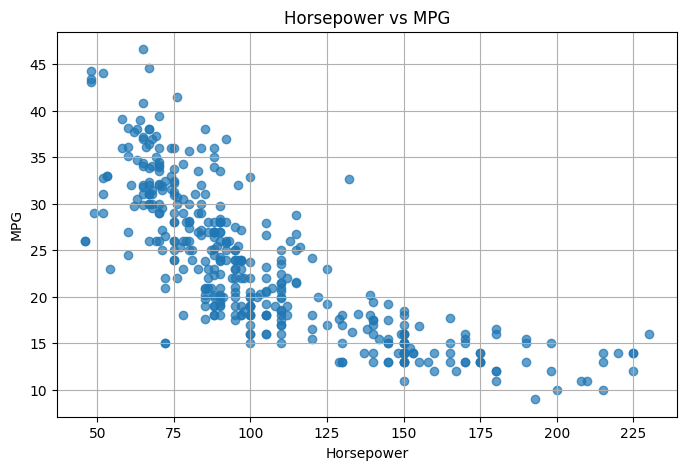

In [5]:

plt.figure(figsize=(8, 5))

plt.scatter(df["horsepower"], df["mpg"], alpha=0.7)

plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.title("Horsepower vs MPG")

plt.grid(True)
plt.show()


## 4. Data Preprocessing

4.1 Separate Features and Target

4.2 Split Data into Training and Testing Sets

4.3 Handle Missing Values

4.4 Polynomial Feature Transformation

4.5 Feature Scaling

4.6 Add Bias Term

In [6]:

X = df[["horsepower"]].values
y = df[["mpg"]].values

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (398, 1)
y shape: (398, 1)


In [7]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 318
Testing samples: 80


In [8]:

imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

print("Missing values handled successfully!")


Missing values handled successfully!


In [9]:

poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

print("Original features:", X_train.shape)
print("Polynomial features:", X_train_poly.shape)

print("\nFirst 5 polynomial samples:")
print(X_train_poly[:5])


Original features: (318, 1)
Polynomial features: (318, 2)

First 5 polynomial samples:
[[  150. 22500.]
 [   88.  7744.]
 [   68.  4624.]
 [   60.  3600.]
 [   95.  9025.]]


In [10]:

scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train_poly)
X_test_scaled = scaler_X.transform(X_test_poly)

# Scale the target values too
scaler_y = StandardScaler()

y_train_scaled = scaler_y.fit_transform(y_train)
y_test_scaled = scaler_y.transform(y_test)

print("Feature scaling completed!")


Feature scaling completed!


In [11]:

# Add bias column to training and testing data

X_train_model = np.c_[
    np.ones((X_train_scaled.shape[0], 1)),
    X_train_scaled
]

X_test_model = np.c_[
    np.ones((X_test_scaled.shape[0], 1)),
    X_test_scaled
]

print("Training shape:", X_train_model.shape)
print("Testing shape:", X_test_model.shape)


Training shape: (318, 3)
Testing shape: (80, 3)


## 5. Model and Loss Function

In [12]:

# Initialize model parameters

n_features = X_train_model.shape[1]

initial_weights = np.zeros((n_features, 1))

print("Initial weights:")
print(initial_weights)


Initial weights:
[[0.]
 [0.]
 [0.]]


In [13]:

def compute_loss(X, y, weights):

    predictions = X @ weights

    #Mean Squared Error (MSE)
    loss = np.mean((predictions - y) ** 2)

    return loss


## 6. Optimization Algorithm

6.4 RMSprop

In [14]:

def compute_gradient(X, y, weights):

    m = len(y)

    predictions = X @ weights

    gradient = (2 / m) * X.T @ (predictions - y)

    return gradient


## 7. Train the Model

In [15]:
def train_rmsprop(learning_rate=0.01, epochs=500,
                  beta=0.9, epsilon=1e-8):

    weights = np.zeros((X_train_model.shape[1], 1))

    squared_gradients = np.zeros_like(weights)

    loss_history = []

    start_time = time.time()

    for epoch in range(epochs):

        gradient = compute_gradient(
            X_train_model,
            y_train_scaled,
            weights
        )

        squared_gradients = (
            beta * squared_gradients
            + (1 - beta) * (gradient ** 2)
        )

        weights -= (
            learning_rate * gradient
            / (np.sqrt(squared_gradients) + epsilon)
        )

        epoch_loss = compute_loss(
            X_train_model,
            y_train_scaled,
            weights
        )

        loss_history.append(epoch_loss)

    training_time = time.time() - start_time

    return weights, loss_history, training_time

In [16]:
# Train using RMSprop
weights_rmsprop, loss_history_rmsprop, training_time_rmsprop = train_rmsprop()

# Print Results
print("RMSprop Final Loss:", loss_history_rmsprop[-1])
print("RMSprop Training Time:", training_time_rmsprop)
print("RMSprop Final Weights:")
print(weights_rmsprop)

RMSprop Final Loss: 0.3368715441943391
RMSprop Training Time: 0.025417804718017578
RMSprop Final Weights:
[[ 0.00499999]
 [-2.20884881]
 [ 1.4774387 ]]


## 8. Visualizing Training Loss

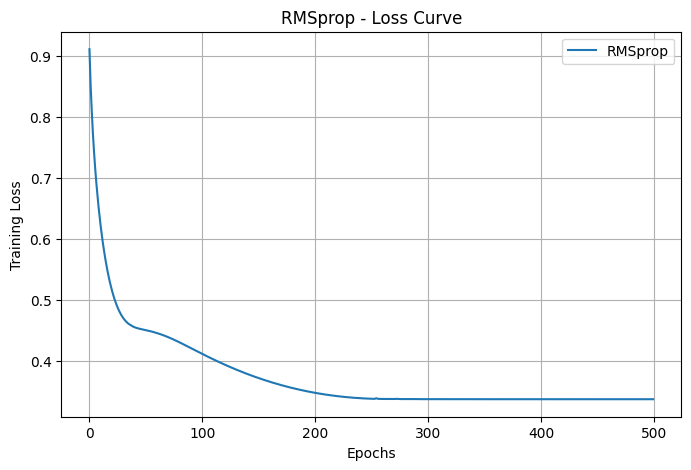

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history_rmsprop, label="RMSprop")

plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.title("RMSprop - Loss Curve")

plt.legend()
plt.grid(True)
plt.show()

## 9. Model Evaluation

In [18]:
# Predictions using RMSprop
y_pred_rmsprop_scaled = X_test_model @ weights_rmsprop

# Convert predictions back to original scale
y_pred_rmsprop = scaler_y.inverse_transform(y_pred_rmsprop_scaled)

# Evaluate RMSprop
print("RMSprop Evaluation:")
print("MSE:", mean_squared_error(y_test, y_pred_rmsprop))
print("MAE:", mean_absolute_error(y_test, y_pred_rmsprop))
print("R2 Score:", r2_score(y_test, y_pred_rmsprop))

RMSprop Evaluation:
MSE: 13.924371383302196
MAE: 2.922399834106438
R2 Score: 0.7410211572101197


## 10. Compare Results

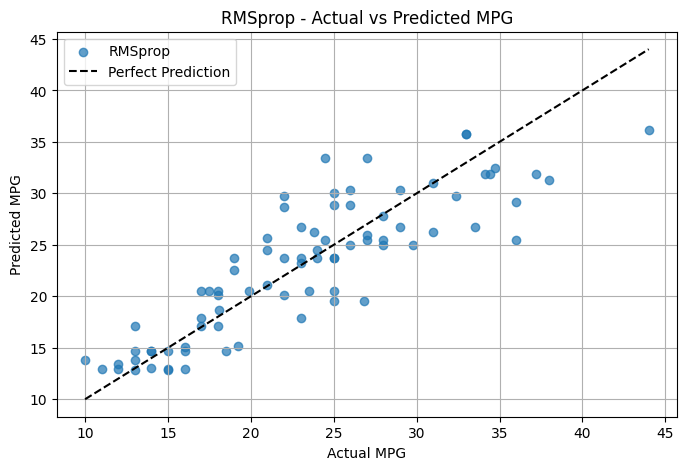

In [19]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_rmsprop, label="RMSprop", alpha=0.7)

# Perfect prediction line
min_value = y_test.min()
max_value = y_test.max()

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    'k--',
    label="Perfect Prediction"
)

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("RMSprop - Actual vs Predicted MPG")

plt.legend()
plt.grid(True)
plt.show()

## Conclusion

In this notebook, Polynomial Regression (degree 2) was implemented using the RMSprop optimization algorithm to predict fuel efficiency (MPG) from horsepower. The same dataset and preprocessing steps were applied to maintain consistency with the previous experiments.

RMSprop adapts the step size of each parameter using a moving average of squared gradients. With learning rate 0.01 it reached a training loss of about 0.337 within 500 epochs (test R² ≈ 0.74), matching the best results of the other methods and converging much faster than plain GD. Because the learning rate is fixed, the weights keep oscillating by roughly one step size around the optimum (visible in the bias term being ~0.005 instead of ~0); a decaying learning rate would remove this.

The model was evaluated with MSE, MAE and R² on the test set, and the loss curve and actual-vs-predicted plot were used to analyze the optimization.